# 7 Minutes to Pywaterflood

This notebook is the first full pass through a waterflood: load rates, history-match
a capacitance-resistance model (CRM), read the well-pair connectivities, check the
fit, and forecast a short injection plan.

History matching uses a Deep-CRM physics-informed network. After `fit()`, `predict()`
uses the identified connectivities and time constants in the closed-form CRM, so a
new injection schedule does not need retraining.

Install with `pip install pywaterflood` if you are on Colab or a fresh environment.


In [1]:
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pywaterflood import CRM, CrmCompensated


from pathlib import Path

import pandas as pd


def load_sample_rates():
    """Load the 4-producer / 5-injector sample (local clone or GitHub)."""
    for folder in (Path("../../testing/data"), Path("testing/data")):
        if (folder / "production.csv").exists():
            root = folder
            prod = pd.read_csv(root / "production.csv", header=None)
            inj = pd.read_csv(root / "injection.csv", header=None)
            time = pd.read_csv(root / "time.csv", header=None)
            return prod, inj, time
    gh = "https://raw.githubusercontent.com/frank1010111/pywaterflood/master/testing/data/"
    prod = pd.read_csv(gh + "production.csv", header=None)
    inj = pd.read_csv(gh + "injection.csv", header=None)
    time = pd.read_csv(gh + "time.csv", header=None)
    return prod, inj, time


## 1. Rate data

CRM wants three arrays that share a time axis:

| Array | Shape | Role |
|---|---|---|
| production | `(n_time, n_producers)` | producer columns, fixed order |
| injection | `(n_time, n_injectors)` | injector columns, fixed order |
| time | `(n_time,)` | elapsed time (same unit as $\tau$) |

Rates must be non-negative and finite. Use reservoir volume per time if formation
volume factors matter on your field. A shut-in well is a column of zeros.


production (298, 4)  injection (298, 5)  time (298,)
time span: 31.0 → 9070.0
mean production by well: [693.2 704.  697.8 708.7]
mean injection by well:  [563.5 419.4 742.9 487.2 592.7]


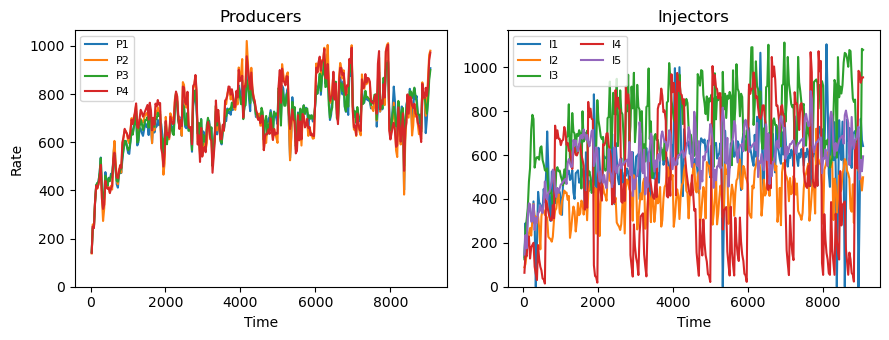

In [2]:
prod, inj, time = load_sample_rates()
t = time.to_numpy()[:, 0]
q = prod.to_numpy()
i = inj.to_numpy()
producer_ids = [f"P{k+1}" for k in range(q.shape[1])]
injector_ids = [f"I{k+1}" for k in range(i.shape[1])]

print(f"production {q.shape}  injection {i.shape}  time {t.shape}")
print(f"time span: {t[0]:.1f} → {t[-1]:.1f}")
print("mean production by well:", np.round(q.mean(axis=0), 1))
print("mean injection by well: ", np.round(i.mean(axis=0), 1))

fig, (ax_p, ax_i) = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True)
for k, name in enumerate(producer_ids):
    ax_p.plot(t, q[:, k], label=name)
for k, name in enumerate(injector_ids):
    ax_i.plot(t, i[:, k], label=name)
ax_p.set(title="Producers", xlabel="Time", ylabel="Rate", ylim=(0, None))
ax_i.set(title="Injectors", xlabel="Time", ylim=(0, None))
ax_p.legend(fontsize=8)
ax_i.legend(fontsize=8, ncol=2)
fig.tight_layout()


## 2. History match (CRM-IP)

The default that uses the model fully on a typical pattern flood:

- `primary=True` — keep a depletion term from the first observed rate
- `tau_selection="per-pair"` — one time constant per injector–producer pair (CRM-IP)
- `constraints="up-to one"` — each injector’s gains sum to at most 1

`epochs` is the PINN training length (default 2000). A few hundred steps is enough
to see structure on this sample. Set `seed` for a repeatable start.


RMSE by producer: [31.45 38.38 28.35 34.83]
overall RMSE: 33.463274743269736


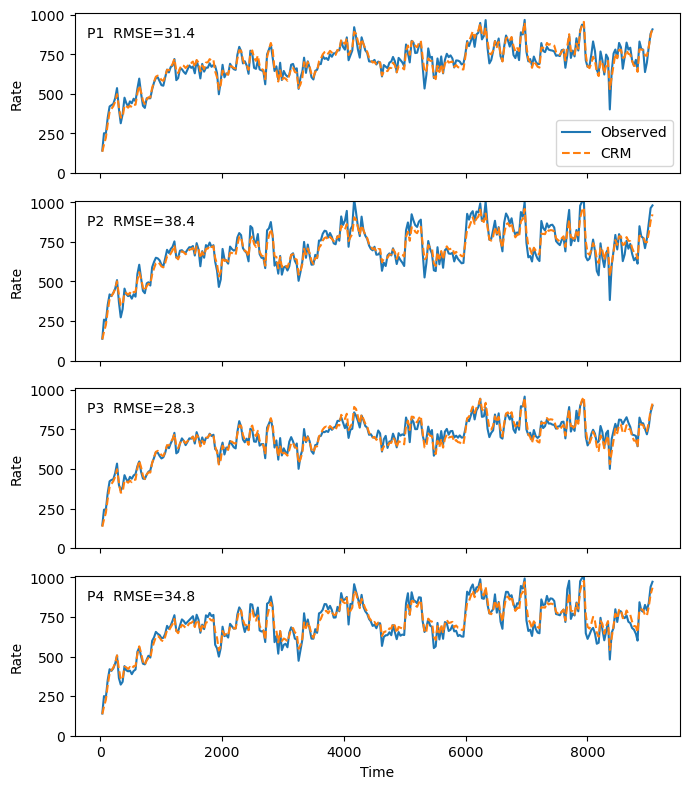

In [3]:
n_threads = max(1, min(os.cpu_count() or 1, q.shape[1]))

crm = CRM(primary=True, tau_selection="per-pair", constraints="up-to one")
crm.fit(q, i, t, epochs=250, seed=0, num_cores=n_threads)
q_hat = crm.predict()
resid = crm.residual()
rmse = np.sqrt(np.mean(resid**2, axis=0))
print("RMSE by producer:", np.round(rmse, 2))
print("overall RMSE:", float(np.sqrt(np.mean(resid**2))))

fig, axes = plt.subplots(len(producer_ids), figsize=(7, 8), sharex=True, sharey=True)
for k, name in enumerate(producer_ids):
    axes[k].plot(t, q[:, k], label="Observed")
    axes[k].plot(t, q_hat[:, k], ls="--", label="CRM")
    axes[k].set(ylabel="Rate", ylim=(0, None))
    axes[k].text(0.02, 0.85, f"{name}  RMSE={rmse[k]:.1f}", transform=axes[k].transAxes)
axes[0].legend(loc="lower right")
axes[-1].set(xlabel="Time")
fig.tight_layout()


## 3. Interwell connectivity

`crm.gains` has shape `(n_producers, n_injectors)`. Entry `[j, i]` is the fraction of
injector $i$ that supports producer $j$. With `"up-to one"`, each injector column
sums to $\le 1$. The leftover $1 - \sum_j f_{ij}$ is injection that does not show
up at these producers (aquifer, unswept rock, measurement error).


In [4]:
gains = pd.DataFrame(crm.gains, index=producer_ids, columns=injector_ids)
display(gains.style.background_gradient(cmap="Reds", axis=None).format("{:.3f}"))
print("sum by injector (≤ 1):", np.round(gains.sum(axis=0).to_numpy(), 3))
print("sum by producer:      ", np.round(gains.sum(axis=1).to_numpy(), 3))

tau = pd.DataFrame(crm.tau, index=producer_ids, columns=injector_ids)
print("\nTime constants τ")
display(tau.style.format("{:.1f}"))


,I1,I2,I3,I4,I5
P1,0.246,0.252,0.249,0.247,0.247
P2,0.254,0.245,0.250,0.253,0.249
P3,0.247,0.251,0.250,0.244,0.247
P4,0.253,0.252,0.251,0.256,0.257


sum by injector (≤ 1): [1. 1. 1. 1. 1.]
sum by producer:       [1.24  1.251 1.24  1.269]

Time constants τ


,I1,I2,I3,I4,I5
P1,28.0,28.0,28.0,28.0,28.0
P2,28.0,28.0,28.0,28.0,28.0
P3,28.0,28.0,28.0,28.0,28.0
P4,28.0,28.0,28.0,28.0,28.0


Training diagnostics live in `crm.loss_history_`. Data loss is rate MSE. Physics
loss is the CRM differential-equation residual. Both should fall. If data goes to
zero and physics stays huge, the networks are memorizing rates — raise
`physics_weight` or train longer (see the choosing-CRM notebook).


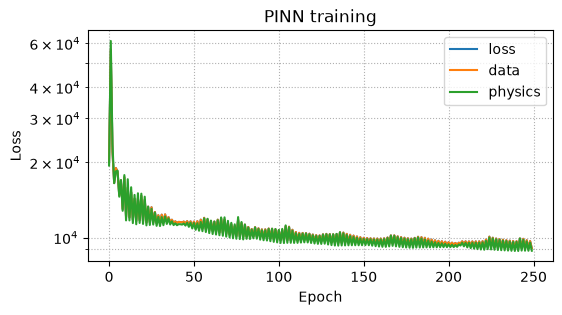

In [5]:
hist = pd.DataFrame(crm.loss_history_)
ax = hist[["loss", "data", "physics"]].plot(figsize=(6, 3))
ax.set(xlabel="Epoch", ylabel="Loss", yscale="log", title="PINN training")
ax.grid(True, which="both", ls=":")


## 4. Forecast a new injection plan

`predict(injection, time)` is the closed-form CRM. To keep memory of the history,
concatenate the historical rates with the plan and slice the tail. Here we hold the
last observed injection for 12 extra steps.


planned production, last step: [934.6 944.6 934.  956.1]


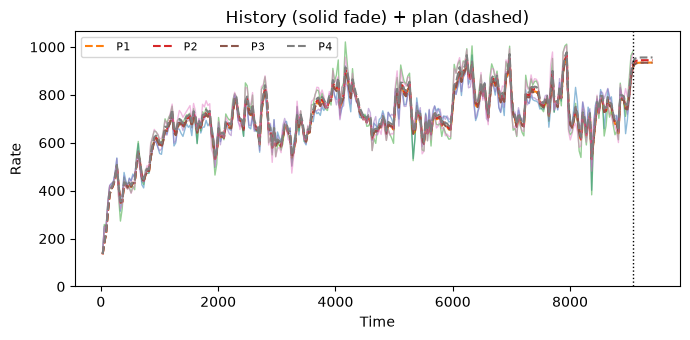

In [6]:
dt = t[1] - t[0]
n_future = 12
t_future = t[-1] + dt * np.arange(1, n_future + 1)
i_future = np.repeat(i[[-1], :], n_future, axis=0)

t_all = np.concatenate([t, t_future])
i_all = np.vstack([i, i_future])
q_all = crm.predict(i_all, t_all)
q_plan = q_all[len(t) :]

fig, ax = plt.subplots(figsize=(7, 3.5))
for k, name in enumerate(producer_ids):
    ax.plot(t, q[:, k], lw=1, alpha=0.5)
    ax.plot(t_all, q_all[:, k], ls="--", label=name)
ax.axvline(t[-1], color="k", ls=":", lw=1)
ax.set(xlabel="Time", ylabel="Rate", ylim=(0, None), title="History (solid fade) + plan (dashed)")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
print("planned production, last step:", np.round(q_plan[-1], 1))


## 5. Two upgrades that use the rest of the library

**Producer BHP.** If you measure bottomhole pressure, `CrmCompensated` adds
$\tau J \dot p_{wf}$ so a choke change is not explained as a new injector
connection. The pressure below is synthetic (declining with rate) so the API is
visible; replace it with real BHP on a field.

**Well map.** If you have $X,Y$ locations, seed $f_{ij}$ from geometry instead of
a uniform start. That path is the MPI notebook (`initial_guess="geometry"`).


In [7]:
pressure = 1000.0 - 0.1 * q  # demo only; use measured BHP in production
crm_p = CrmCompensated(primary=True, tau_selection="per-pair", constraints="up-to one")
crm_p.fit(q, pressure, i, t, epochs=120, seed=0, num_cores=n_threads)
q_hat_p = crm_p.predict()
rmse_p = np.sqrt(np.mean((q - q_hat_p) ** 2, axis=0))
print("CRM RMSE:             ", np.round(rmse, 2))
print("CrmCompensated RMSE:  ", np.round(rmse_p, 2))

# crm.to_excel("crm_history_match.xlsx")
# crm.to_pickle("crm_history_match.pkl")
print("gains shape", crm.gains.shape, "| tau shape", crm.tau.shape)


CRM RMSE:              [31.45 38.38 28.35 34.83]
CrmCompensated RMSE:   [37.22 38.78 37.56 37.92]
gains shape (4, 5) | tau shape (4, 5)


## Next

- [Choosing your CRM](choosing-crm.ipynb) — CRM-IP vs CRM-P vs CRM-T, constraints, PINN knobs
- [Multiwell productivity index](multiwell-productivity-index.ipynb) — geometry seed for $f_{ij}$
- [Buckley-Leverett](buckley-leverett.ipynb) — front speed on a pair CRM trusts
- [Aquifer](aquifer.ipynb) — influx when production exceeds injection
